# Math to Deep Learning with PyTorch: Step-by-Step Notebooks
## Part 4 — Loss Functions, Gradient Descent and Optimization

### 📚 Series

| Part | Notebook |
|---|---|
| 1 | [Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-1-derivatives) |
| 2 | [Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func) |
| 3 | [Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-3-small-nn) |
| 4 | [Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz) |
| 5 | [Training Neural Networks End-to-End in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-5-end2end-nn-training) |

## Goal

In the previous parts we learned how to build neurons and layers, use activation functions, and call `loss.backward()`.

Now we focus on two key questions:

1. **How do we measure how wrong the model is?** → Loss Function.
2. **How do we change the weights to reduce the loss?** → Optimizer.

After this notebook, you should understand `MSE`, `MAE`, `BCE`, `CrossEntropy`, learning rate, and the practical differences between `SGD`, `Momentum`, and `Adam`.

## Setup

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


# 1. What Is a Loss Function?

A loss function turns model error into **one number**. Smaller loss usually means predictions are closer to targets.

```text
input → model → prediction
                  │
target ───────────┘
        ↓
      loss
```

During training we compute $\partial L/\partial\theta$ and use this gradient to update parameters.

# 2. Mean Squared Error (MSE)

For regression, a common loss is:

$$\operatorname{MSE}=\frac{1}{N}\sum_{i=1}^{N}(\hat y_i-y_i)^2$$

Large errors are penalized more strongly because they are squared. In PyTorch: `nn.MSELoss()`.

In [2]:
prediction = torch.tensor([2.0, 4.0, 8.0])
target = torch.tensor([3.0, 5.0, 5.0])

mse_manual = ((prediction-target)**2).mean()
mse_torch = nn.MSELoss()(prediction, target)

print("prediction:", prediction)
print("target:", target)
print("manual MSE:", mse_manual.item())
print("PyTorch MSE:", mse_torch.item())

prediction: tensor([2., 4., 8.])
target: tensor([3., 5., 5.])
manual MSE: 3.6666667461395264
PyTorch MSE: 3.6666667461395264


# 3. Mean Absolute Error (MAE)

MAE uses the absolute difference:

$$\operatorname{MAE}=\frac{1}{N}\sum_{i=1}^{N}|\hat y_i-y_i|$$

In PyTorch: `nn.L1Loss()`.

In [3]:
mae_manual = (prediction-target).abs().mean()
mae_torch = nn.L1Loss()(prediction, target)
print("manual MAE:", mae_manual.item())
print("PyTorch MAE:", mae_torch.item())

manual MAE: 1.6666666269302368
PyTorch MAE: 1.6666666269302368


# 4. MSE vs MAE

For one error $e=\hat y-y$:

$$L_{MSE}=e^2,\qquad L_{MAE}=|e|$$

MSE grows quadratically and is therefore much more sensitive to large errors.

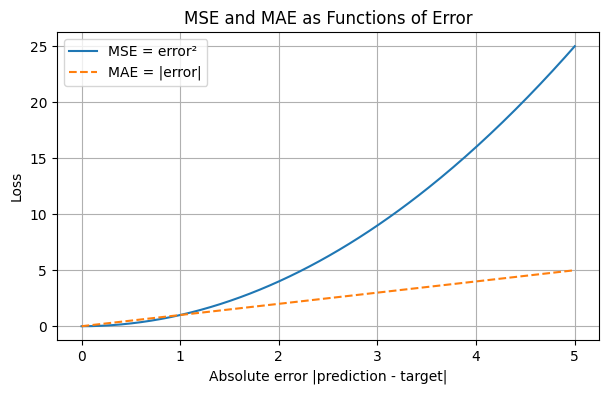

In [4]:
errors = torch.linspace(0,5,200)
plt.figure(figsize=(7,4))
plt.plot(errors.numpy(), (errors**2).numpy(), label="MSE = error²")
plt.plot(errors.numpy(), errors.numpy(), "--", label="MAE = |error|")
plt.xlabel("Absolute error |prediction - target|")
plt.ylabel("Loss")
plt.title("MSE and MAE as Functions of Error")
plt.legend()
plt.grid(True)
plt.show()

# 5. Binary Cross-Entropy (BCE)

For binary classification, $y\in\{0,1\}$ and $0<p<1$:

$$L=-[y\log(p)+(1-y)\log(1-p)]$$

A confident correct prediction has small loss; a confident wrong prediction has large loss.

In [5]:
probs = torch.tensor([0.9,0.6,0.1])
y1 = torch.ones_like(probs)
bce = -(y1*torch.log(probs)+(1-y1)*torch.log(1-probs))
for p,l in zip(probs,bce):
    print(f"p={p.item():.1f} -> BCE={l.item():.4f}")

p=0.9 -> BCE=0.1054
p=0.6 -> BCE=0.5108
p=0.1 -> BCE=2.3026


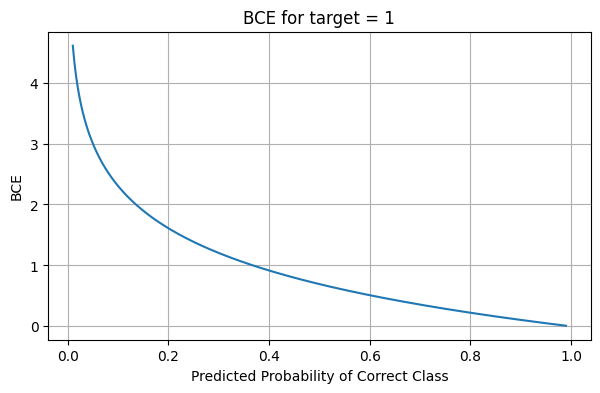

In [6]:
p=torch.linspace(0.01,0.99,300)
plt.figure(figsize=(7,4))
plt.plot(p.numpy(), (-torch.log(p)).numpy())
plt.xlabel("Predicted Probability of Correct Class")
plt.ylabel("BCE")
plt.title("BCE for target = 1")
plt.grid(True)
plt.show()

# 6. `BCEWithLogitsLoss`: the Practical Version

In practice, instead of separate `sigmoid → BCELoss`, we usually use `nn.BCEWithLogitsLoss()`. It accepts raw **logits** and combines sigmoid + BCE in a numerically stable way.

In [7]:
logits=torch.tensor([-2.0,0.0,2.0])
targets=torch.tensor([0.0,1.0,1.0])
criterion=nn.BCEWithLogitsLoss(reduction="none")
losses=criterion(logits,targets)
print("logits:",logits)
print("probabilities:",torch.sigmoid(logits))
print("targets:",targets)
print("losses:",losses)

logits: tensor([-2.,  0.,  2.])
probabilities: tensor([0.1192, 0.5000, 0.8808])
targets: tensor([0., 1., 1.])
losses: tensor([0.1269, 0.6931, 0.1269])


# 7. Cross-Entropy for Multiple Classes

For multi-class classification we use `nn.CrossEntropyLoss()`. The model returns logits $[z_1,\dots,z_K]$, while the target is the correct class index. Do **not** manually apply softmax before `CrossEntropyLoss`.

In [8]:
logits=torch.tensor([[2.0,0.5,-1.0],[0.2,0.3,2.2]])
targets=torch.tensor([0,2])
loss=nn.CrossEntropyLoss()(logits,targets)
print("softmax probabilities:",torch.softmax(logits,dim=1))
print("targets:",targets)
print("CrossEntropy loss:",loss.item())

softmax probabilities: tensor([[0.7856, 0.1753, 0.0391],
        [0.1053, 0.1164, 0.7783]])
targets: tensor([0, 2])
CrossEntropy loss: 0.2459976077079773


# 8. Which Loss Should You Use?

| Task | Typical loss |
|---|---|
| Regression | `MSELoss`, `L1Loss` |
| Binary classification | `BCEWithLogitsLoss` |
| Multi-class classification | `CrossEntropyLoss` |

# 9. Gradient Descent

After computing the loss, we update parameters:

$$\theta_{new}=\theta_{old}-\eta\nabla_\theta L$$

where $\eta$ is the learning rate. We move **against the gradient** because the gradient points toward the steepest increase of the loss.

# 10. One Gradient Descent Step by Hand

Consider $L(w)=(w-3)^2$. Its minimum is at $w=3$, and:

$$\frac{dL}{dw}=2(w-3)$$

We start from $w=0$ and perform one update.

In [9]:
w=0.0
lr=0.1
loss=(w-3)**2
grad=2*(w-3)
w_new=w-lr*grad
print("old w =",w)
print("loss =",loss)
print("gradient =",grad)
print("new w =",w_new)
print("new loss =",(w_new-3)**2)

old w = 0.0
loss = 9.0
gradient = -6.0
new w = 0.6000000000000001
new loss = 5.76


# 11. Learning Rate

The learning rate controls the step size. Too small means slow learning; too large can overshoot the minimum or diverge.

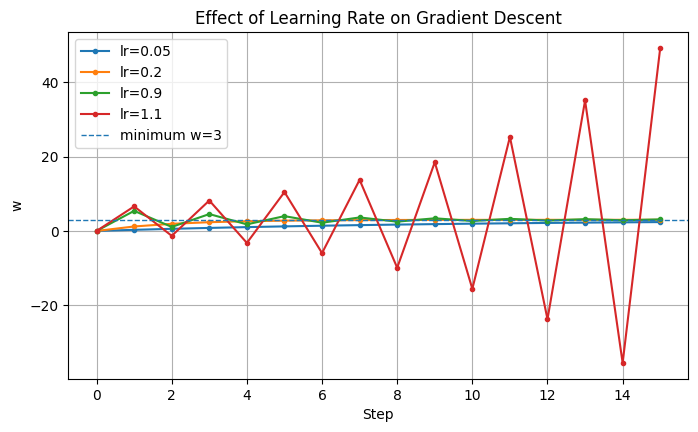

In [10]:
def gd(lr,steps=15):
    w=0.0
    h=[w]
    for _ in range(steps):
        w=w-lr*2*(w-3)
        h.append(w)
    return h

plt.figure(figsize=(8,4.5))
for lr in [0.05,0.2,0.9,1.1]:
    h=gd(lr)
    plt.plot(range(len(h)),h,marker="o",markersize=3,label=f"lr={lr}")
plt.axhline(3.0,linestyle="--",linewidth=1,label="minimum w=3")
plt.xlabel("Step")
plt.ylabel("w")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()

# 12. SGD in PyTorch

`torch.optim.SGD` implements the basic update:

$$w\leftarrow w-\eta\frac{\partial L}{\partial w}$$

In [11]:
w=torch.tensor(0.0,requires_grad=True)
optimizer=torch.optim.SGD([w],lr=0.1)
for step in range(5):
    optimizer.zero_grad()
    loss=(w-3)**2
    loss.backward()
    optimizer.step()
    print(f"step={step+1}: w={w.item():.4f}, loss={loss.item():.4f}")

step=1: w=0.6000, loss=9.0000
step=2: w=1.0800, loss=5.7600
step=3: w=1.4640, loss=3.6864
step=4: w=1.7712, loss=2.3593
step=5: w=2.0170, loss=1.5099


# 13. Momentum

Momentum adds inertia:

$$v_t=\beta v_{t-1}+g_t,\qquad w_t=w_{t-1}-\eta v_t$$

In PyTorch: `torch.optim.SGD(..., momentum=0.9)`.

In [12]:
w=torch.tensor(0.0,requires_grad=True)
optimizer=torch.optim.SGD([w],lr=0.1,momentum=0.9)
for step in range(5):
    optimizer.zero_grad()
    loss=(w-3)**2
    loss.backward()
    optimizer.step()
    print(f"step={step+1}: w={w.item():.4f}, loss={loss.item():.4f}")

step=1: w=0.6000, loss=9.0000
step=2: w=1.6200, loss=5.7600
step=3: w=2.8140, loss=1.9044
step=4: w=3.9258, loss=0.0346
step=5: w=4.7413, loss=0.8571


# 14. Adam

`Adam` adapts updates using statistics of recent gradients. It is a convenient optimizer to try first in many tasks, but the learning rate still matters.

In [13]:
w=torch.tensor(0.0,requires_grad=True)
optimizer=torch.optim.Adam([w],lr=0.2)
for step in range(5):
    optimizer.zero_grad()
    loss=(w-3)**2
    loss.backward()
    optimizer.step()
    print(f"step={step+1}: w={w.item():.4f}, loss={loss.item():.4f}")

step=1: w=0.2000, loss=9.0000
step=2: w=0.3995, loss=7.8400
step=3: w=0.5982, loss=6.7625
step=4: w=0.7956, loss=5.7687
step=5: w=0.9913, loss=4.8594


# 15. Comparing SGD, Momentum, and Adam

We compare optimizers on the same regression problem:

$$y=3x-2,\qquad \hat y=wx+b$$

Every optimizer starts from exactly the same parameter values.

In [14]:
torch.manual_seed(42)
X=torch.linspace(-2,2,80).unsqueeze(1)
y=3*X-2

class LRModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear=nn.Linear(1,1)
    def forward(self,x):
        return self.linear(x)

base=LRModel()
state={k:v.detach().clone() for k,v in base.state_dict().items()}

def train(kind,epochs=80):
    m=LRModel(); m.load_state_dict(state)
    if kind=="SGD": opt=torch.optim.SGD(m.parameters(),lr=0.08)
    elif kind=="Momentum": opt=torch.optim.SGD(m.parameters(),lr=0.08,momentum=0.9)
    else: opt=torch.optim.Adam(m.parameters(),lr=0.08)
    crit=nn.MSELoss(); hist=[]
    for _ in range(epochs):
        opt.zero_grad()
        pred=m(X)
        loss=crit(pred,y)
        loss.backward()
        opt.step()
        hist.append(loss.item())
    return m,hist

results={name:train(name) for name in ["SGD","Momentum","Adam"]}
for name,(m,h) in results.items():
    print(f"{name:8s} final loss={h[-1]:.6f}, w={m.linear.weight.item():.4f}, b={m.linear.bias.item():.4f}")

SGD      final loss=0.000000, w=3.0000, b=-2.0000
Momentum final loss=0.001749, w=2.9817, b=-1.9960
Adam     final loss=0.003689, w=2.9834, b=-2.0540


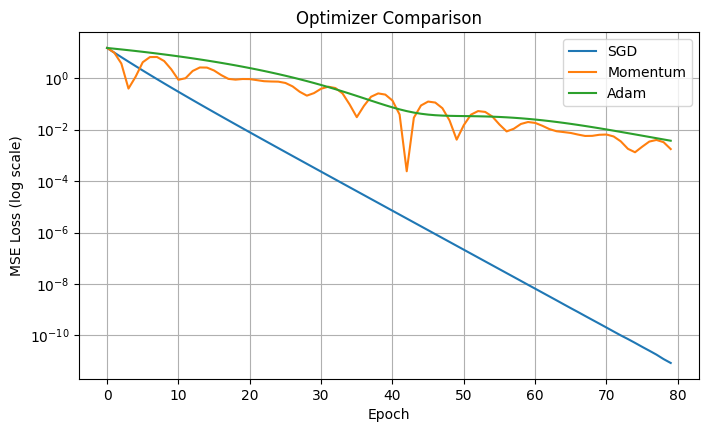

In [15]:
plt.figure(figsize=(8,4.5))
for name,(_,h) in results.items():
    plt.plot(h,label=name)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (log scale)")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid(True)
plt.show()

# 16. The Standard Training Loop

A basic PyTorch training loop:

```python
optimizer.zero_grad()
prediction = model(X)
loss = criterion(prediction, y)
loss.backward()
optimizer.step()
```

1. `zero_grad()` clears old gradients.
2. `model(X)` runs the forward pass.
3. `criterion` computes the loss.
4. `backward()` computes gradients.
5. `step()` updates parameters.

In [16]:
model=nn.Linear(1,1)
criterion=nn.MSELoss()
optimizer=torch.optim.SGD(model.parameters(),lr=0.05)
for epoch in range(5):
    optimizer.zero_grad()
    prediction=model(X)
    loss=criterion(prediction,y)
    loss.backward()
    optimizer.step()
    print(f"epoch={epoch+1}, loss={loss.item():.4f}")

epoch=1, loss=7.7390
epoch=2, loss=5.8715
epoch=3, loss=4.4599
epoch=4, loss=3.3920
epoch=5, loss=2.5831


# Checks

# 17. Small Exercises

### Exercise 1
For prediction `8` and target `5`, compute the one-example MSE manually.

### Exercise 2
Compare MSE and MAE for errors `1, 2, 5, 10`.

### Exercise 3
For target `y=1`, compare BCE for `p=0.9`, `0.6`, `0.1`.

### Exercise 4
For $L(w)=(w-3)^2$, try learning rates `0.01`, `0.1`, `0.9`, `1.1`.

### Exercise 5
Change learning rates in the optimizer comparison and see whether the fastest optimizer changes.

In [17]:
prediction=torch.tensor([8.0])
target=torch.tensor([5.0])
print("MSE:",nn.MSELoss()(prediction,target).item())
print("MAE:",nn.L1Loss()(prediction,target).item())

MSE: 9.0
MAE: 3.0


# 18. Quick Cheat Sheet

| Concept | Meaning |
|---|---|
| loss | one number measuring error |
| MSE | squared error |
| MAE / L1 | absolute error |
| BCE | binary classification |
| logits | raw model outputs |
| CrossEntropy | multi-class classification |
| Gradient Descent | move against the gradient |
| learning rate | optimizer step size |
| SGD | basic gradient update |
| Momentum | adds inertia |
| Adam | adaptive optimizer |
| `zero_grad()` | clears gradients |
| `backward()` | computes gradients |
| `step()` | updates parameters |

# Next Steps

We now have almost the complete learning mechanism: `data → model → prediction → loss → backward → optimizer`. In Part 5 we will combine everything into a full end-to-end pipeline.

## ➡️ Next Notebook

[**Part 5 — Training Neural Networks End-to-End in PyTorch**](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-5-end2end-nn-training)

Planned topics: train/test split, Dataset/DataLoader, batches, model, loss, optimizer, training/validation loops, accuracy, `model.train()` / `model.eval()`, and prediction on new data.

### Full Series

| Part | Notebook |
|---|---|
| 1 | [Derivatives, Gradients and Backpropagation](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-1-derivatives) |
| 2 | [Activation Functions and the Chain Rule](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-2-activation-func) |
| 3 | [Building a Small Neural Network in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-3-small-nn) |
| 4 | [Loss Functions, Gradient Descent and Optimization](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-4-loss-gd-optimiz) |
| 5 | [Training Neural Networks End-to-End in PyTorch](https://www.kaggle.com/code/kupershtein/math-to-dl-with-pytorch-part-5-end2end-nn-training) |